In [ ]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
df=pd.read_csv('customer_churn.csv',true_values=['Yes'],false_values=['No'])

In [2]:
df.shape

(7043, 21)

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,True,False,1,False,No phone service,DSL,No,...,No,No,No,No,Month-to-month,True,Electronic check,29.85,29.85,False
1,5575-GNVDE,Male,0,False,False,34,True,No,DSL,Yes,...,Yes,No,No,No,One year,False,Mailed check,56.95,1889.5,False
2,3668-QPYBK,Male,0,False,False,2,True,No,DSL,Yes,...,No,No,No,No,Month-to-month,True,Mailed check,53.85,108.15,True
3,7795-CFOCW,Male,0,False,False,45,False,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,False,Bank transfer (automatic),42.30,1840.75,False
4,9237-HQITU,Female,0,False,False,2,True,No,Fiber optic,No,...,No,No,No,No,Month-to-month,True,Electronic check,70.70,151.65,True


In [4]:
df.dtypes 

customerID           object
gender               object
SeniorCitizen         int64
Partner                bool
Dependents             bool
tenure                int64
PhoneService           bool
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling       bool
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                  bool
dtype: object

In [5]:
#all unique categorical values of all features 
for col in df.columns: 
    print(f"Column: '{col}'               ({df[col].nunique()} unique values)=>                   {df[col].unique()}")


Column: 'customerID'               (7043 unique values)=>                   ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
Column: 'gender'               (2 unique values)=>                   ['Female' 'Male']
Column: 'SeniorCitizen'               (2 unique values)=>                   [0 1]
Column: 'Partner'               (2 unique values)=>                   [ True False]
Column: 'Dependents'               (2 unique values)=>                   [False  True]
Column: 'tenure'               (73 unique values)=>                   [ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]
Column: 'PhoneService'               (2 unique values)=>                   [False  True]
Column: 'MultipleLines'               (3 unique values)=>                   ['No phone service' 'No' 'Yes']
Column: 

In [6]:
# need to manage customerID and TotalCharges initially to stop columns explosion in onehot encoding 
df['TotalCharges']=pd.to_numeric(df['TotalCharges'].str.strip())
df['SeniorCitizen']=df['SeniorCitizen'].astype(bool)

#adding new features
services=['PhoneService','MultipleLines','OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']
service_df=df[services].copy()
for col in services:
    if service_df[col].dtype == bool:
        pass
    else:
        service_df[col]=service_df[col].str.strip().str.lower()=='yes'
df['Total_Services'] = service_df.sum(axis=1)

df['Automatic_payment']=df['PaymentMethod'].isin(['Bank transfer (automatic)','Credit card (automatic)'])

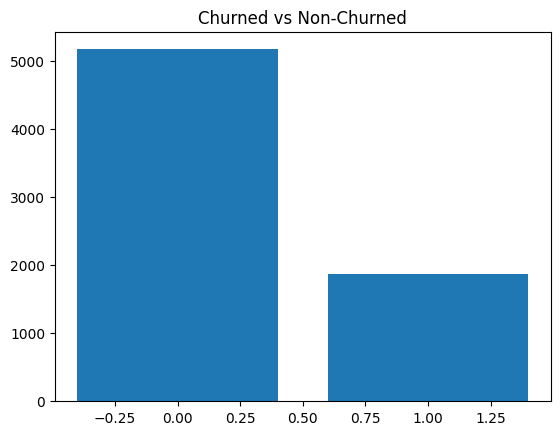

In [7]:
churn_counts=df['Churn'].value_counts()
plt.bar(df['Churn'].unique(),churn_counts)
plt.title('Churned vs Non-Churned')
plt.show()
# use imbalanced method for class_weight if the target class weight difference is extremely high 

In [8]:
df.isnull().sum()   

customerID            0
gender                0
SeniorCitizen         0
Partner               0
Dependents            0
tenure                0
PhoneService          0
MultipleLines         0
InternetService       0
OnlineSecurity        0
OnlineBackup          0
DeviceProtection      0
TechSupport           0
StreamingTV           0
StreamingMovies       0
Contract              0
PaperlessBilling      0
PaymentMethod         0
MonthlyCharges        0
TotalCharges         11
Churn                 0
Total_Services        0
Automatic_payment     0
dtype: int64

In [9]:
customerid_code=df['customerID'].str.split('-',expand=True)[1]
customerid_code.nunique()    # to see if any part of customerid has any pattern or useful information

7040

In [10]:
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer

x=df.drop(columns=['Churn','customerID'])
y=df['Churn']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

imputer=SimpleImputer(strategy='median')
x_train['TotalCharges']=imputer.fit_transform(x_train[['TotalCharges']])
x_test['TotalCharges']=imputer.transform(x_test[['TotalCharges']])

In [11]:
# mutual information 
from sklearn.feature_selection import mutual_info_classif
def get_mutual_info_scores(x,y):
    temp_x=x.copy()
    for col in temp_x.select_dtypes([bool,object]):
        temp_x[col],_=temp_x[col].factorize()
    discrete_features=[pd.api.types.is_integer_dtype(type) for type in temp_x.dtypes]
    mi_scores=mutual_info_classif(temp_x,y,discrete_features=discrete_features,random_state=1)
    mi_scores=pd.Series(mi_scores,name='MI_score', index=temp_x.columns).sort_values(ascending=False)
    return mi_scores

Text(0.5, 1.0, "Mutual information of features with 'Churn'")

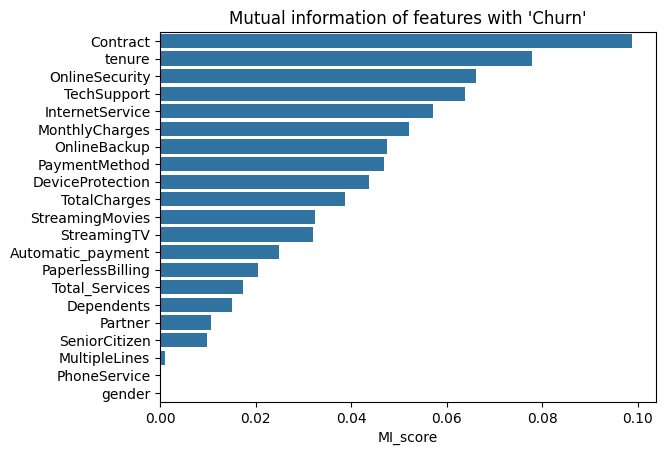

In [12]:
mi_scores=get_mutual_info_scores(x_train,y_train)
plot=sns.barplot(data=mi_scores,orient='h')
plot.set_title("Mutual information of features with 'Churn'")

<Axes: xlabel='gender', ylabel='Count'>

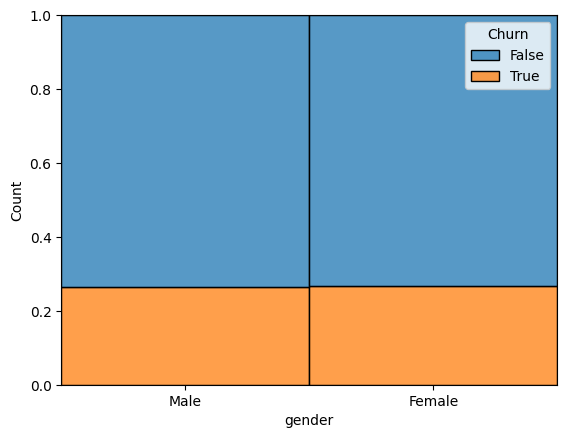

In [13]:
sns.histplot(data=x_train,x='gender',hue=y_train,multiple='fill')

In [14]:
x_train=x_train.drop(columns=['gender'])
x_test=x_test.drop(columns=['gender'])

In [15]:
from sklearn.preprocessing  import StandardScaler, OneHotEncoder

num_cols=[col for col in x_train.columns if x_train[col].dtypes in [float,int]]
cat_cols=list(set(x_train.columns)-set(num_cols))
preprocessor=ColumnTransformer(
    transformers=[('num',StandardScaler(),num_cols),
                  ('cat',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cat_cols)]
).set_output(transform='pandas')
x_train_processed=preprocessor.fit_transform(x_train)
x_test_processed=preprocessor.transform(x_test)

In [16]:
x_train_processed.shape

(5634, 47)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from functools import partial
from sklearn.model_selection import StratifiedKFold

score_func=partial(mutual_info_classif,random_state=41)
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

In [25]:
lr=LogisticRegression(verbose=0,random_state=1,class_weight='balanced',penalty='elasticnet',solver='saga')
params_grid1={
    'C':[0.8,1,1.2],
    'l1_ratio':[0,0.3,0.6,1],
    'max_iter':[600,900,1200],
}
grid1=GridSearchCV(estimator=lr,param_grid=params_grid1,cv=cv,scoring='roc_auc')
grid1.fit(x_train_processed,y_train)

,estimator,LogisticRegre...solver='saga')
,param_grid,"{'C': [0.8, 1, ...], 'l1_ratio': [0, 0.3, ...], 'max_iter': [600, 900, ...]}"
,scoring,'roc_auc'
,n_jobs,None
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'elasticnet'


In [26]:
grid1.best_score_

np.float64(0.8461694042675475)

In [27]:
rfc=RandomForestClassifier(random_state=1,class_weight='balanced')

params_grid2={
    'max_depth':[None,4,8],
    'n_estimators':[50,100,150],
    'min_samples_split':[2,4,6],
    'min_samples_leaf':[1,2,3]
}
grid2=GridSearchCV(estimator=rfc,param_grid=params_grid2,cv=cv,scoring='roc_auc')
grid2.fit(x_train_processed,y_train)

,estimator,RandomForestC...andom_state=1)
,param_grid,"{'max_depth': [None, 4, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 4, ...], 'n_estimators': [50, 100, ...]}"
,scoring,'roc_auc'
,n_jobs,None
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,150


In [28]:
grid2.best_score_

np.float64(0.8466157112312505)

In [18]:
scale_weight=y_train[y_train==0].count()/y_train[y_train==1].count()
scale_weight

np.float64(2.768561872909699)

In [20]:
xgb=XGBClassifier(verbosity=0,device='cuda',tree_method='hist',random_state=42,scale_pos_weight=round(scale_weight),
                  sampling_method='gradient_based',feature_selector='shuffle') 

params_grid3 ={
    'n_estimators':[100,200,300],
    'learning_rate':[0.01,0.1,0.2],
    'max_depth':[4,6,8],
    'reg_lambda':[0,10,20],
    'colsample_bytree':[0.4,0.5,0.6,0.7],
    'min_child_weight':[4,6,8],
    'gamma':[4,8]
    }
grid3=GridSearchCV(estimator=xgb,param_grid=params_grid3,cv=cv,scoring='roc_auc')
grid3.fit(x_train_processed,y_train)

,estimator,"XGBClassifier...obs=None, ...)"
,param_grid,"{'colsample_bytree': [0.4, 0.5, ...], 'gamma': [4, 8], 'learning_rate': [0.01, 0.1, ...], 'max_depth': [4, 6, ...], ...}"
,scoring,'roc_auc'
,n_jobs,None
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,objective,'binary:logistic'


In [21]:
grid3.best_score_

np.float64(0.8493186377488741)

In [22]:
grid3.best_params_

{'colsample_bytree': 0.7,
 'gamma': 8,
 'learning_rate': 0.2,
 'max_depth': 6,
 'min_child_weight': 4,
 'n_estimators': 100,
 'reg_lambda': 20}

In [23]:
from sklearn.metrics import confusion_matrix
y_predict=grid3.best_estimator_.predict(x_test_processed)
confusion_matrix(y_test,y_predict)

array([[753, 282],
       [ 73, 301]])

In [104]:
#scale_pos_weight managed  by lookig at confusion matrix 
model=XGBClassifier(verbosity=0,device='cpu',tree_method='hist',random_state=42,scale_pos_weight=2.3,
                    colsample_bytree=0.7,gamma=8,learning_rate=0.15,max_depth=5,min_child_weight=3,n_estimators=150,reg_lambda=20,subsample=0.7) 

model.fit(x_train_processed,y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.7
,device,'cpu'
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


In [105]:
from sklearn.metrics import confusion_matrix,classification_report,roc_auc_score

y_predict=model.predict(x_test_processed)
print(confusion_matrix(y_test,y_predict))
print(classification_report(y_test,y_predict))

[[792 243]
 [ 81 293]]
              precision    recall  f1-score   support

       False       0.91      0.77      0.83      1035
        True       0.55      0.78      0.64       374

    accuracy                           0.77      1409
   macro avg       0.73      0.77      0.74      1409
weighted avg       0.81      0.77      0.78      1409



In [106]:
y_train_predict=model.predict_proba(x_train_processed)[:,1]
roc_auc_score(y_train,y_train_predict)

0.8632970819216185

In [107]:
y_predict_probab=model.predict_proba(x_test_processed)[:,1]
roc_auc_score(y_test,y_predict_probab)

0.8499082900617426

<Axes: >

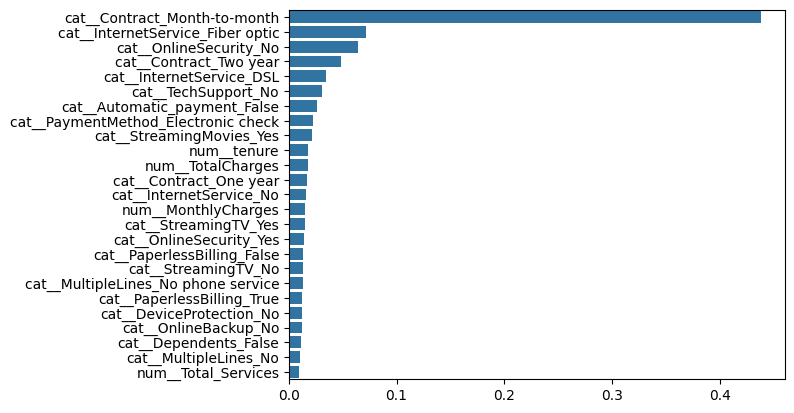

In [108]:
importance_s=pd.Series(model.feature_importances_,index=x_train_processed.columns).sort_values(ascending=False)
sns.barplot(importance_s.head(25),orient='h')

<Axes: xlabel='importance', ylabel='feature'>

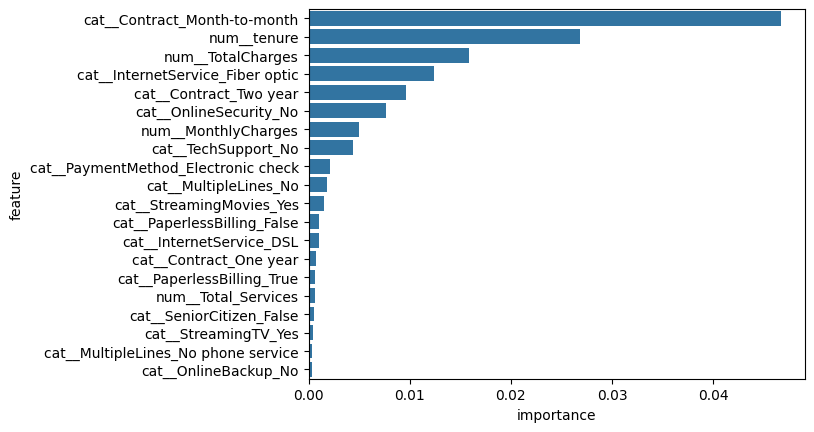

In [109]:
from sklearn.inspection import permutation_importance
result=permutation_importance(model,x_test_processed,y_test,n_repeats=10,random_state=42,scoring='roc_auc')
importance_df=pd.DataFrame({'feature':x_test_processed.columns,'importance':result.importances_mean,
                         'std':result.importances_std}).sort_values(by='importance',ascending=False)
sns.barplot(data=importance_df.head(20),x='importance',y='feature')

In [277]:
# checking particular index 
idx=int(input("Enter an index(0-1408)from x_test_final dataset to compare actual and predicted result:"))
print(f"Actual result(Churn) at index {idx} : {'Yes' if y_test.iloc[idx]==1 else 'No'}")
predicted_value=model.predict(x_test_processed.iloc[[idx]])
final_result='Yes' if predicted_value==1 else 'No'
print(f"Predicted result(Churn) at index {idx} : {final_result}")

Actual result(Churn) at index 1111 : No
Predicted result(Churn) at index 1111 : No


/home/umesh/ML/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


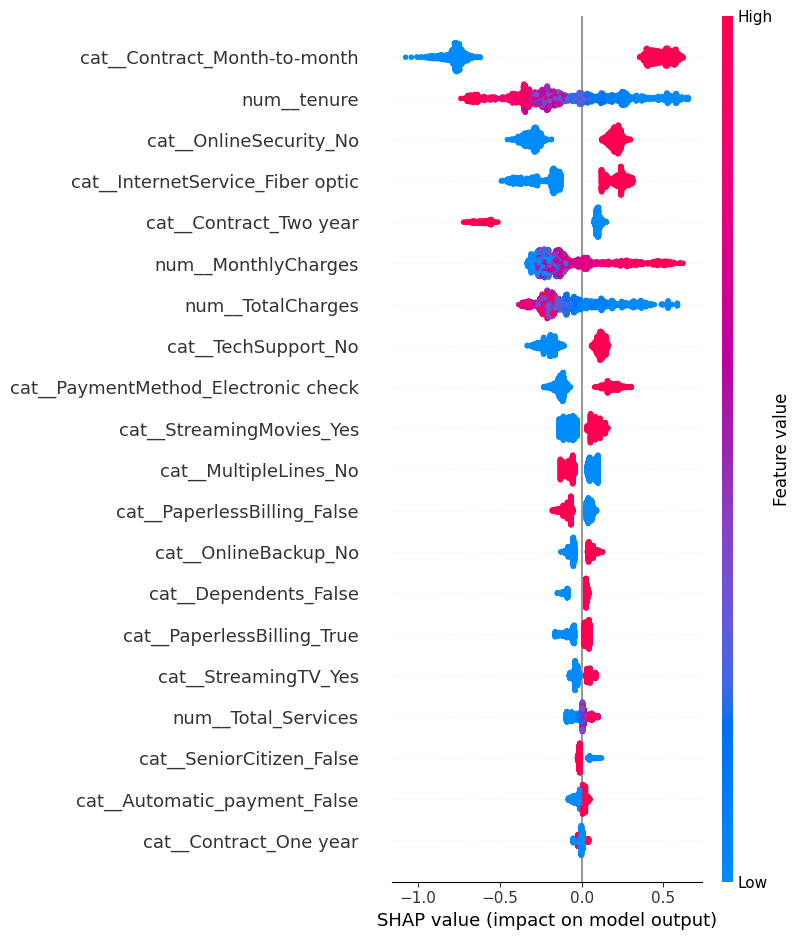

In [110]:
import shap 
explainer=shap.TreeExplainer(model) 
shap_values=explainer(x_test_processed)
shap.summary_plot(shap_values,x_test_processed,max_display=20)